# Lab 1 - Processing and analysing pulsar data <br><span style="color:gray;font-size:20px">Introduction to Radio Astronomy 2023/2024.<br>Lecturer: Prof. J. P. McKean.<br>Notebook created by D. Konijn adapted from A. Lafontaine and R. Luichies </span>

This Jupyter notebook is supposed to act as a guided walkthrough for processing and analysing observed pulsar data coming from the Dwingeloo Telescope. The majority of the analysis steps in the notebook are accompanied by explanatory code, as this is not the main goal of this lab. There are however some steps in the analysis (<span style="color:blue">indicated by the blue font</span>) that are left as an exercise for the students. These steps require you to make choices on how you want to process your data. Different methods will lead to different results. Explaining the motivation for the chosen methods should be integrated into the final report. At some places suggestions for expanding on your results can be found in <span style="color:green">green</span>. These are not mandatory, but might help you with writing a better report and getting more interesting results.

Here we take a look at some previously observed data of the pulsar PSR B0329+54, also called the "homepulsar". This pulsar is very bright and consistent, making it good data for explaining some of the generally important steps in pulsar data analysis. 

From the data we will determine a period ($P$), a dispersion measure ($DM$) and a pulse profile.

For the first part we will use an archived dataset from an observation of B0329+54 one of your groups did. This data is straight from the telescope back-end, meaning no flagging or folding has been performed yet!

Note that the dataset is quite large at ~1 GB.

In [1]:
from blimpy import Waterfall
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq
from scipy.signal import argrelmax
from scipy.optimize import curve_fit
from scipy.stats import linregress

wf = Waterfall("2025-11-13_1009_B0329+54.fil")

In [2]:
%matplotlib inline

In [3]:
data = wf.data

In [4]:
data = data[:,0,:]

In [5]:
data = data.T # I flip to get freqs on y axis

In [6]:
dt = wf.header['tsamp']

In [7]:
vmin=np.nanpercentile(data, 5)
vmax=np.nanpercentile(data, 95)

In [8]:
dt = wf.header["tsamp"]
duration = data.shape[1] * dt
print("New shape: {} time bins by {} frequency channels".format(*data.shape))
print(f"Total observation time: {duration:.2f}s")

## First bin is reserved as counter and therefore sliced out ##
data = data[1:,:]

wf.info()

New shape: 256 time bins by 976562 frequency channels
Total observation time: 300.00s

--- File Info ---
     rawdatafile :                          unknown
     source_name :                         B0329+54
      machine_id :                                0
    telescope_id :                                0
         src_raj :                          3:33:00
         src_dej :                     54:34:43.601
        az_start :               346.94744541963416
        za_start :                71.29840952510234
       data_type :                                1
            fch1 :                  419.9609375 MHz
            foff :                    -0.078125 MHz
          nchans :                              256
          nbeams :                                0
           ibeam :                                0
           nbits :                               32
   tstart (ISOT) :          2025-11-13T10:09:39.000
    tstart (MJD) :               60992.423368055854
           

## Inspecting and flagging the data
Let's take a look at the raw data by making a waterfall plot (dynamic spectrum) of the entire observation.

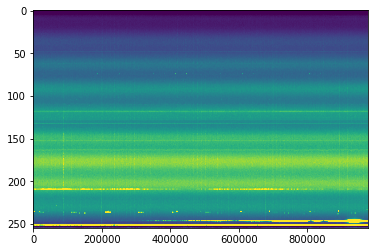

In [9]:
plt.figure()
plt.imshow(data, aspect='auto', vmin=vmin, vmax=vmax)
plt.show()

   <span style="color:blue"><b>Exercise:</b> Flag your data to get rid of RFI and/or other interfering signals. <br>You can make this as complex, simple, manual or automatic as you want as long as your choices have a good argumentation. Can you for example improve on the simple flagging by threshold method?</span>

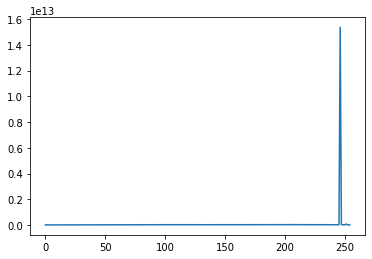

In [10]:
plt.plot(np.sum(data, axis=1))

#add your own flagging!
#or use np.mean

In [11]:
#purpose of this; cut off the very big peak

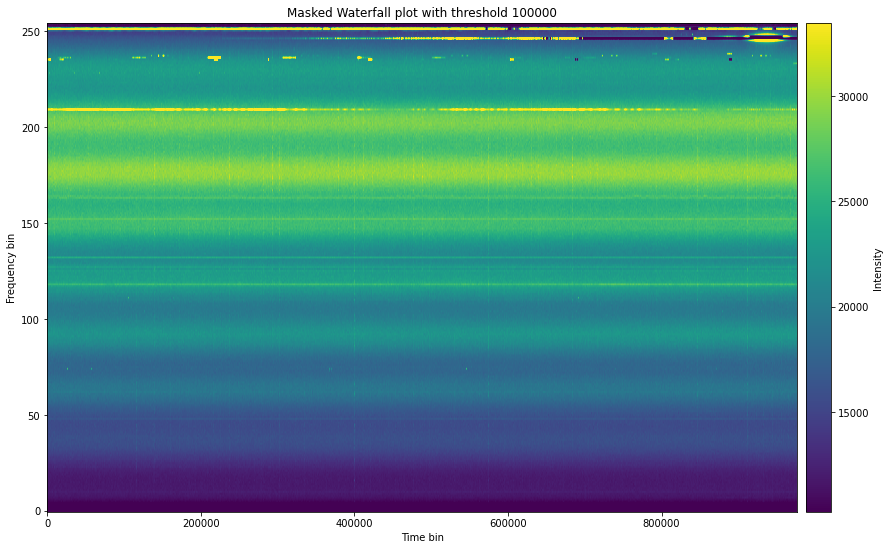

In [12]:
#threshold = 0.1e13 # <- Fill in a threshold value here based on the plot above
threshold = 100000
masked_dat = np.where(data < threshold, data, 0)

fig = plt.figure(figsize = (16,9))
frame = fig.add_subplot(111)
image = frame.imshow(masked_dat, origin='lower',vmin=np.nanpercentile(masked_dat, 5),vmax=np.percentile(masked_dat, 95))

fig.colorbar(image, ax=frame, label='Intensity', pad=0.01)

frame.set_title(f'Masked Waterfall plot with threshold {threshold}')

frame.set_xlabel('Time bin')
frame.set_ylabel('Frequency bin')
frame.set_aspect('auto')

plt.show()

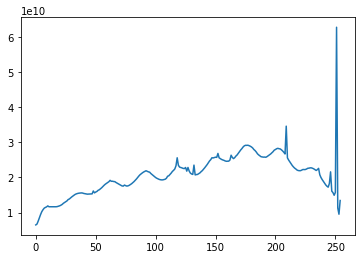

In [13]:
plt.plot(np.sum(masked_dat, axis=1))

In [14]:
# THIS normalised per channel and sets mean = 0 and std = 1 for each channel
masked_dat = (masked_dat - masked_dat.mean(axis=1, keepdims=True)) / masked_dat.std(axis=1, keepdims=True)

If you are content with your flagging choices we can plot the data again. You will most likely require a few flagging iterations before the data starts to look good.

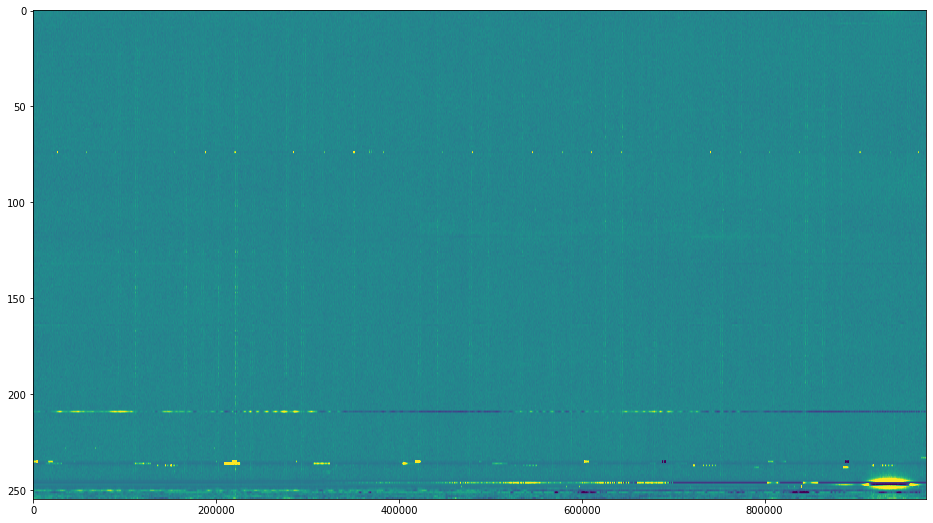

In [15]:
plt.figure(figsize = (16,9))
plt.imshow(masked_dat, aspect='auto', vmin = np.nanpercentile(masked_dat, 5) , vmax = np.nanpercentile(masked_dat, 95))
plt.show()

Instead of looking at the entire time range, let's look at a small portion (first 5000 timebins i.e. first ~2.3 s) and see if we can already spot a pulse.

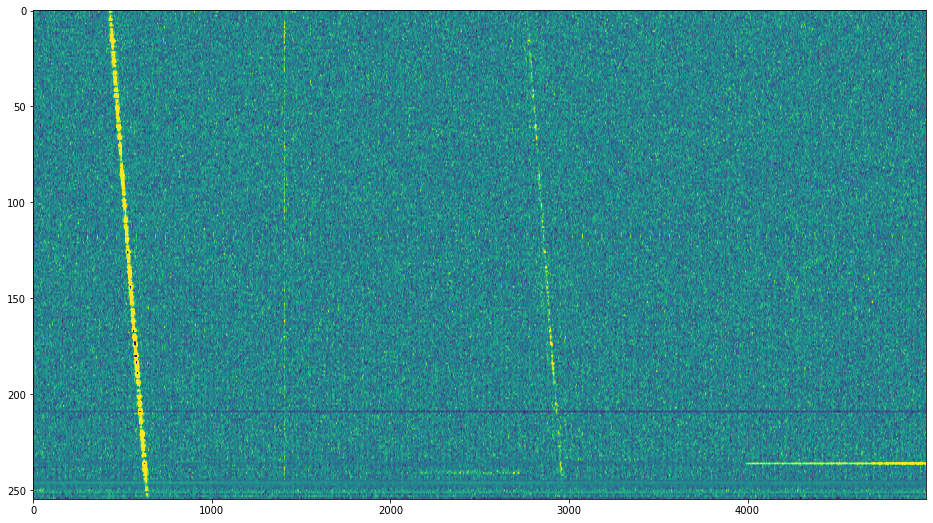

In [16]:
# For the bright pulsar we can already see the pulses!
plt.figure(figsize = (16,9))
sliced_masked = masked_dat[:, 400000:405000]
plt.imshow(sliced_masked, aspect='auto', vmin = np.nanpercentile(sliced_masked, 5) , vmax = np.nanpercentile(sliced_masked, 95))
plt.show()
#black dots are gone because of flagging

We see some pulses!! We can also see how the pulse is affected by the interfering free electrons as a function of frequency. The higher frequencies of the pulse arrive earlier than the lower frequencies of the pulse. The emerging slope can be used to determine the dispersion measure ($DM$) of this pulsar. Measuring the slope with the data in its current form is however not so easy, so we will get back to that later. 

Another parameter we can determine is the period ($P$) of the pulsar. From the distance between the pulses you can already make an estimate by eye of what the pulsar's period roughly is.

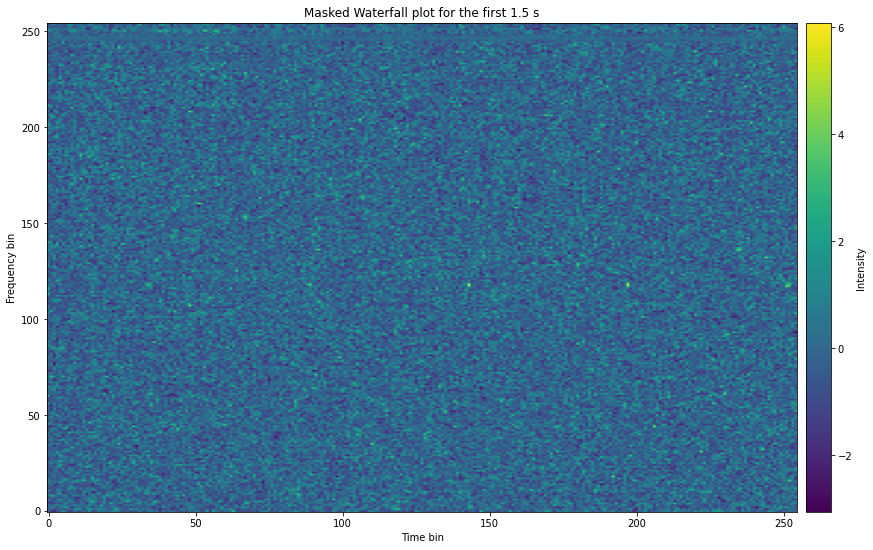

In [17]:
### Inspecting a small portion of the masked data ###
freq_bins = slice(0,255) # number of frequency bins to use
time_bins = 5000         # number of time bins to use

fig = plt.figure(figsize = (16, 9))
frame = fig.add_subplot(111)
image = frame.imshow(sliced_masked[:time_bins, freq_bins], origin='lower')
fig.colorbar(image, ax=frame, label='Intensity', pad=0.01)

frame.set_title(f'Masked Waterfall plot for the first {time_bins*dt:.1f} s')
frame.set_xlabel('Time bin')
frame.set_ylabel('Frequency bin')
frame.set_aspect('auto')

plt.show()

! how do we choose a bin with high S/N? when i try to have more freq bins, and i use a bin with good S/N, then i run the FTT code and it says it's out of the axis of (0,255)

In [18]:
## Enter the index of your frequency bin here ##
#!!##
#5000 bins = 2.3s, consider pulses at timebin 650 and timebin 3000 --> period seems to be 2350 bins
#period_estimate = (2350/5000) * 2.3 = 1.081 s

good_bin = 102

For good bin, check y-axis, this should be the brightest yellow.

## Determining the pulsar period (using Fast Fourier Transform)

Our data contains a periodic signal over a large amount of time. Although one single pulse is not quite strong enough, we can utilize the periodic behaviour and the large observation time to determine the pulsar period. We do this by using a FFT. This will take our data from the time domain to the frequency domain.

Let's do an FFT of our chosen frequency bin and see what we get out:

976562


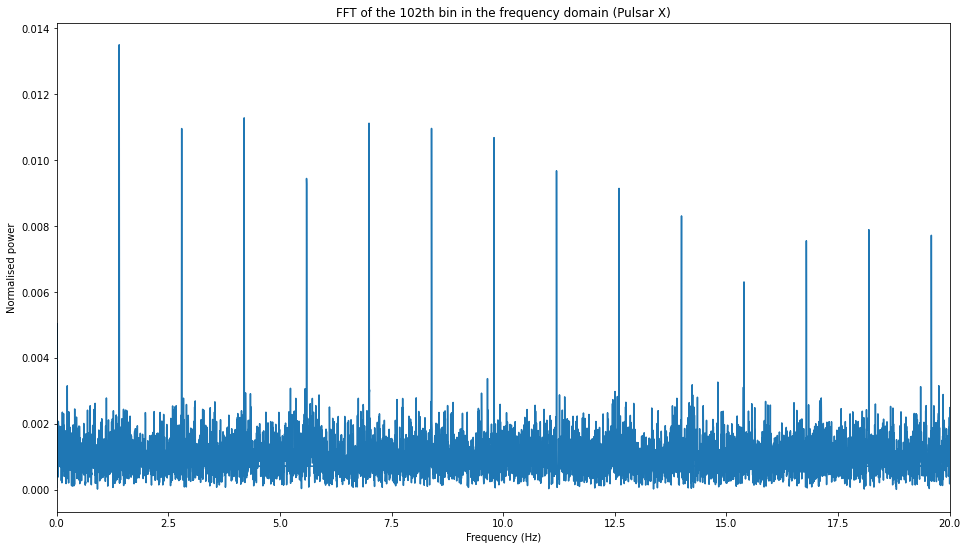

In [19]:
### Defining the data in our frequency bin ###
onebin_data = masked_dat[good_bin, :]
N = len(onebin_data)
print(N)

### Performing an FFT of the data and creating a new frequency array ###
onebin_fft = fft(onebin_data)
fft_freqs = fftfreq(n=N, d=dt)

### Computing the magnitude (absolute) of the data and normalizing with 1/N ###
norm_fft = 1/N * np.abs(onebin_fft)

### Plotting our FFT ###
fig = plt.figure(figsize=(16,9))
frame = fig.add_subplot(111)
frame.plot(fft_freqs, norm_fft)

frame.set_xlim(0, 20)
# frame.set_ylim(0, .02)
frame.set_title(f'FFT of the {good_bin}th bin in the frequency domain (Pulsar X)')
frame.set_xlabel('Frequency (Hz)')
frame.set_ylabel('Normalised power')
frame.set_aspect('auto')

plt.show()

If you have chosen a good frequency bin we can now see that our FFT shows several evenly spaced sharp peaks in the frequency domain. It can thus be seen that there is certainly a periodic signal in our data. The first of these peaks corresponds to the frequency of our pulsar pulse. The next peaks correspond to the first harmonic, second harmonic, etc. and they are all multiples of the pulse frequency. 

To derive a period from this plot we should determine the distance between these peaks as accurately as possible. One way of doing this can be seen in the next cell:

The pulsar period is 0.714528385 ± some error


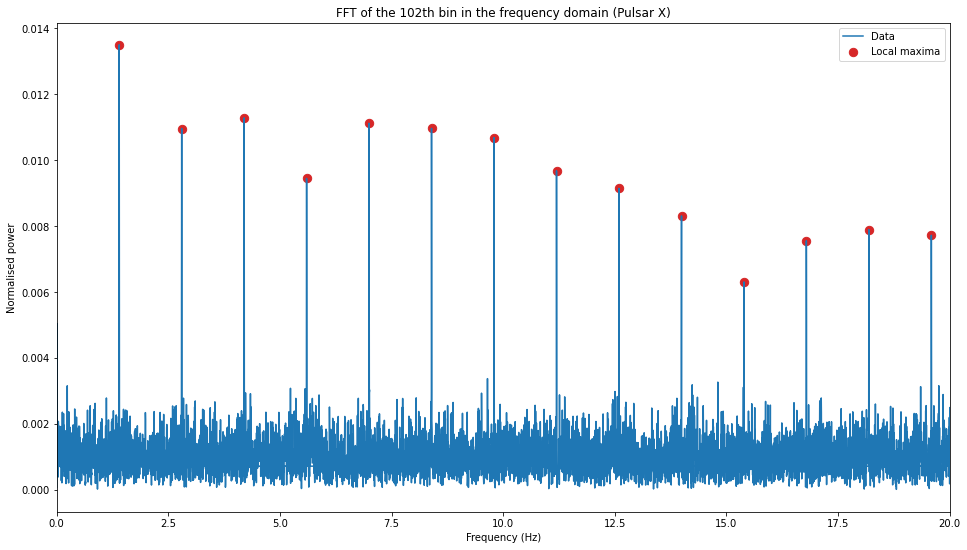

In [20]:
## Determining local maxima in a given frequency range ##
freq_range = (fft_freqs > 0) & (fft_freqs < 20)
local_max_idx = argrelmax(norm_fft[freq_range], order=300)

## Calculating the period ##
N_peaks = len(local_max_idx[0])
final_peak = fft_freqs[freq_range][local_max_idx][-1] #calculates freq of last peak
period = N_peaks / final_peak

print(f"The pulsar period is {period:.9f} \u00B1 some error")

## Inspecting FFT and local maxima ##
fig = plt.figure(figsize=(16,9))
frame = fig.add_subplot(111)
frame.plot(fft_freqs, norm_fft, label='Data')
frame.scatter(fft_freqs[freq_range][local_max_idx], norm_fft[freq_range][local_max_idx], s=70, color='C3', label='Local maxima')
frame.set_xlim(0, 20)

frame.set_title(f'FFT of the {good_bin}th bin in the frequency domain (Pulsar X)')
frame.set_xlabel('Frequency (Hz)')
frame.set_ylabel('Normalised power')
frame.set_aspect('auto')
frame.legend()

plt.show()

<span style="color:blue"><b>Exercise</b>: Determine the error in the period. <br>Your determined period (like all your scientific results) should have an error associated with it. Try to think of how you can assign an error to your frequency data and propagate it using the normal rules for error propagation. Finding the precise error is not the goal here, but you should be able to justify your choice for a reasonable error based on the data so far.</span>

## Folding the data with the found period

With a pulsar period determined we can now use a simple method to increase our S/N. This method is called folding and it makes use of the fact that the pulsar period is very regular, while the RFI and background noise are not. First we slice the data into a number of evenly spaced time chunks of exactly one pulsar period. Then we stack and sum all of these chunks to get out one single time chunk with a significantly increased pulse S/N. This works because all of the pulses will be aligned in position, while the irregular noise and RFI with other periods will be spread around evenly over the rest of the bins. The caveat of this is that folding requires an extremely accurate period determination. Using a slightly inaccurate period would already result in smearing (widening) of the pulse. In the worst case the pulse would be spread out evenly over the time chunk, resulting in nothing indistinguishable noise.

Pulsar periods can be found in a database like for example this one: [https://www.atnf.csiro.au/research/pulsar/psrcat/](https://www.atnf.csiro.au/research/pulsar/psrcat/). It should be noted however that pulsar periods will change over time, meaning the periods in such databases might be outdated. The period we determined for B0329+54 lies close to the literature value of the period ($p = 0.714519699726 {\:\rm s}$), so we will attempt to fold with our own period first.

Another important parameter for folding is the choice for the number of bins for one period chunk. Arguments can be made for both a smaller or larger number of bins. Finding a combination of good S/N and good resolution is preferable. Play around with this until you are satisfied.

Understanding the folding code below is not important for the lab, but you can find a detiaaled explanation of the previous version [here](https://www.astro.rug.nl/intranet/courses/PROGNUM2022/build/html/Notebooks/Students2017_2018/nb_std_alferink.html). I have altered it slightly as to how I would have done this. 

<span style="color:blue"><b>Exercise:</b> Find a good number of bins for your folding algorithm and try folding with the code below. You can try multiple number of bins and compare the difference between them.</span>

In [21]:
nbins = 250
#what works well: 200, 300, 250 
#difference: they're shifted slightly to the left/right, but same basic pattern

N = masked_dat.shape[1]
t = np.arange(N) * dt
P = period
phase = (t % P) / P  

bins = np.linspace(0, 1, nbins+1)
folded = np.zeros((masked_dat.shape[0], nbins))
counts = np.zeros(nbins)

bin_index = np.digitize(phase, bins) - 1
bin_index = np.clip(bin_index, 0, nbins-1)

for i in range(nbins):
    mask = bin_index == i
    if mask.any():
        folded[:, i] = np.mean(masked_dat[:, mask], axis=1)
        counts[i] = mask.sum()

Let's plot the folded data to see how the folding algorithm did.

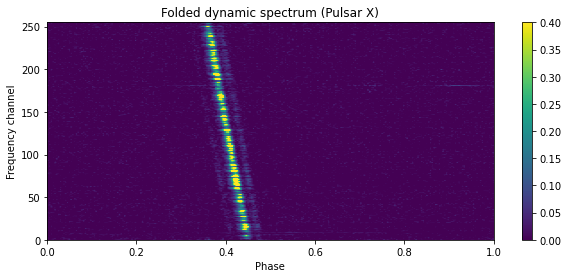

In [22]:
plt.figure(figsize=(10,4))
plt.imshow(np.roll(folded, 300, axis=1), aspect='auto',
           extent=[0,1,0,folded.shape[0]], vmin = 0, vmax = 0.4)
plt.xlabel("Phase")
plt.ylabel("Frequency channel")
plt.title("Folded dynamic spectrum (Pulsar X)")
plt.colorbar()
plt.show()

FFT-derived period: 0.714528385437 s
Gaussian-fit uncertainty (error in mu): ±9.6127e-08 s
FWHM uncertainty: ±4.3574e-06 s


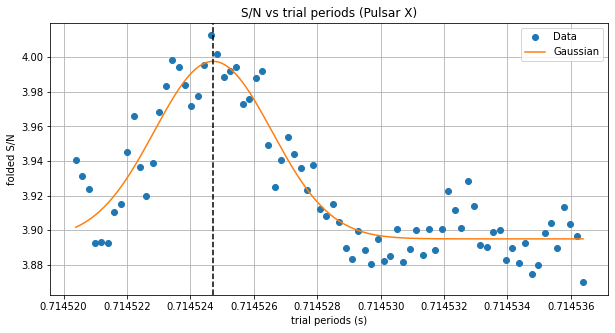

In [36]:
def simple_snr(folded_profile):
    prof = np.mean(folded_profile, axis=0)
    signal = prof.max() - prof.mean()
    noise = prof.std()
    return signal / noise

def gaussian(x, A, mu, sigma, C):
    return A * np.exp(-0.5*((x-mu)/sigma)**2) + C

#scan around  FFT period
P0 = period   
nbins_use = nbins  
dP = 8e-6 #selected by me

trial_periods = np.linspace(P0 - dP, P0 + dP, 80)
snr_vals = []

for Pt in trial_periods: #we refold (uses same code as before)
    N = masked_dat.shape[1]
    t = np.arange(N) * dt
    phase = (t % Pt) / Pt
    bins_edges = np.linspace(0, 1, nbins_use+1)
    folded_tmp = np.zeros((masked_dat.shape[0], nbins_use))

    bin_idx = np.digitize(phase, bins_edges) - 1
    bin_idx = np.clip(bin_idx, 0, nbins_use-1)

    for i in range(nbins_use):
        mask = (bin_idx == i)
        if mask.any():
            folded_tmp[:, i] = masked_dat[:, mask].mean(axis=1)
    snr_vals.append(simple_snr(folded_tmp))

snr_vals = np.array(snr_vals)

A0 = snr_vals.max() - np.median(snr_vals) #these are initial guesses for the params
mu0 = trial_periods[np.argmax(snr_vals)]
sigma0 = (trial_periods[-1]-trial_periods[0])/15
C0 = np.median(snr_vals)

popt, pcov = curve_fit(gaussian, trial_periods, snr_vals, p0=[A0, mu0, sigma0, C0]) #fit gaussian to S/N
A, mu, sigma, C = popt
mu_err = np.sqrt(pcov[1,1])

FWHM = 2.35*sigma

print(f"FFT-derived period: {P0:.12f} s")
print(f"Gaussian-fit uncertainty (error in mu): ±{mu_err:.4e} s")
print(f"FWHM uncertainty: ±{FWHM:.4e} s")

plt.figure(figsize=(10,5))
plt.plot(trial_periods, snr_vals, 'o', label='Data')
xx = np.linspace(trial_periods.min(), trial_periods.max(), 500)
plt.plot(xx, gaussian(xx, *popt), label='Gaussian')
plt.axvline(mu, ls='--', color='k')
plt.xlabel("trial periods (s)")
plt.ylabel("folded S/N")
plt.title("S/N vs trial periods (Pulsar X)")
plt.grid()
plt.legend()
plt.show()

the max S/N is around 0.7145... (where the black line is), and this is the S/N of the peak (which is around 4.05). by seeing where the S/N falls to around half of its value, we can get the FWHM and this can be the error

Wow! 

By adding additional masking and anti-RFI measures, the burst will become even more visible. For our bright burst, we are happy with this!

## Determining the dispersion measure

With a nicely folded pulse we can now tackle the problem of determining the slope or dispersion measure ($DM$) of our pulse. The dispersion measure is the measure at which different frequencies of the pulse are delayed in space through interfering free electrons. The time delay that the photons experience can be described by:

$$\Delta t \:[\rm s] = \frac{1}{2.41\times 10^{-4}} \cdot \frac{DM}{\nu^2 \:[\rm MHz]} + {\rm constant} $$

We can thus try to determine a dispersion measure by rewriting the above equation to a model for DM and fitting it through our peak data.

At first sight you might think that the slope in our data is constant, and thus that $DM \propto \nu$ (constant slope), but in theory this is not the case. The constant slope only seems plausible here due to the fact that our observation has a relatively small total bandwidth (~35 MHz).

<span style="color:blue"><b>Exercise:</b> Define a model for the dispersion measure and fit it through your data. In addition, try also fitting a linear slope and compare the different results. See if you can backup the theory and provide results that agree with the $DM \propto \nu^2$ relation.</span>

In [24]:
def DM_model(freq,DM,offset):
    delta_t = 1/(2.41*10**(-4))*DM/(freq**2)+offset
    return delta_t

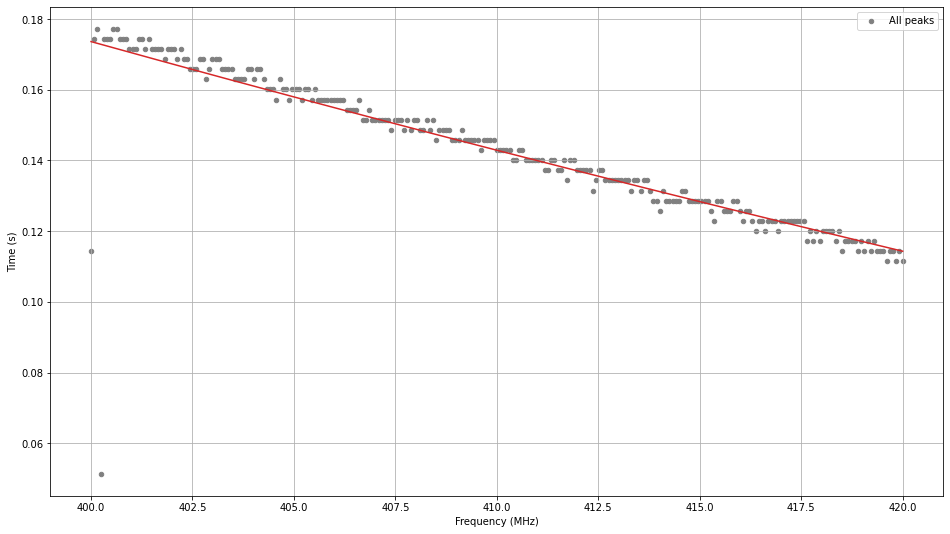

Dispersion measure: 24.583307960835494


In [25]:
t_bin_max = folded.argmax(axis=1)
mask = t_bin_max > 0
freq_bin = np.where(mask)[0]
t_bin    = t_bin_max[mask]

freqs = np.linspace(420, 400, folded.shape[0])
max_freqs = freqs[freq_bin]
max_times = t_bin * period/nbins

popt0, _ = curve_fit(DM_model, max_freqs, max_times, p0=[30, 0.0])
DM0, off0 = popt0

residuals = max_times - DM_model(max_freqs, DM0, off0)

popt, pcov = curve_fit(DM_model, max_freqs, max_times, p0=[DM0, off0])
DM, offset = popt
DM_err, offset_err = np.sqrt(pcov.diagonal())

freqfit = np.linspace(max_freqs.min(), max_freqs.max(), 2000)

plt.figure(figsize=(16,9))
plt.scatter(max_freqs, max_times, s=20, color="gray", alpha=1, label="All peaks")
plt.plot(freqfit, DM_model(freqfit, DM, offset), color="C3")
plt.xlabel("Frequency (MHz)")
plt.ylabel("Time (s)")
plt.grid(True)
plt.legend()
plt.show()

print(f"Dispersion measure: {DM}")

We can see that some max points are not from our burst, likely RFI. $\textbf{ This will influence the fitting!! }$

Linear fit slope: -3.101e-03 s/MHz
Linear fit intercept: 1.415094 s


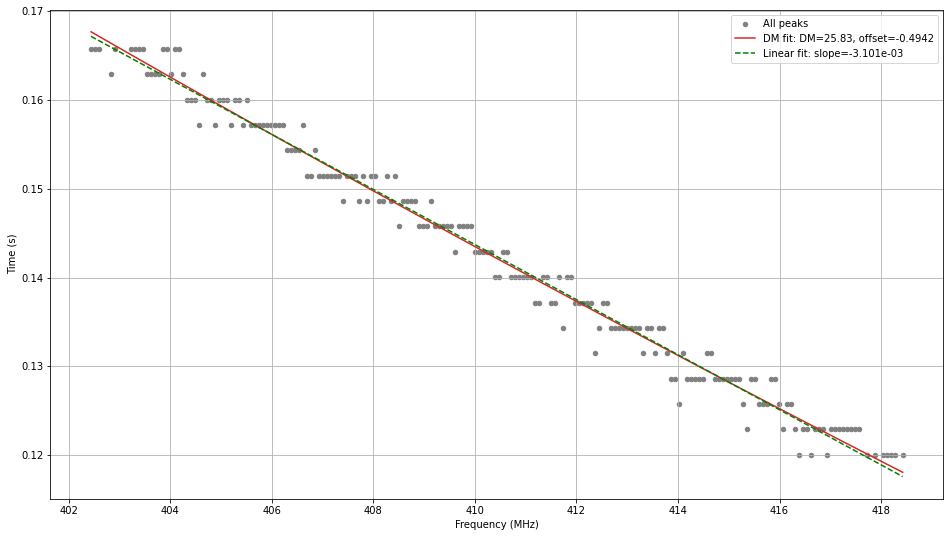

Dispersion measure: 25.834224996443954


In [26]:
low = np.percentile(max_times, 10)
high = np.percentile(max_times, 90)
good_mask = (max_times > low) & (max_times < high)

masked_freqs = max_freqs[good_mask]
masked_times = max_times[good_mask]

popt, pcov = curve_fit(DM_model, masked_freqs, masked_times, p0=[DM0, off0])
DM1, offset1 = popt
DM_err1, offset_err1 = np.sqrt(pcov.diagonal())

freqfit1 = np.linspace(masked_freqs.min(), masked_freqs.max(), 2000)

slope1, intercept1, r_value1, p_value1, std_err1 = linregress(masked_freqs, masked_times) #linear fit

print(f"Linear fit slope: {slope1:.3e} s/MHz")
print(f"Linear fit intercept: {intercept1:.6f} s")

## Generate fitted line for plotting
linear_fit_times1 = slope1 * freqfit1 + intercept1

## Plotting ##
plt.figure(figsize=(16,9))
plt.scatter(masked_freqs, masked_times, s=20, color="gray", alpha=1, label="All peaks")
plt.plot(freqfit1, DM_model(freqfit1, DM1, offset1), color="C3", label=f"DM fit: DM={DM1:.2f}, offset={offset1:.4f}")
plt.plot(freqfit1, linear_fit_times1, color="green", linestyle="--", label=f"Linear fit: slope={slope1:.3e}")
plt.xlabel("Frequency (MHz)")
plt.ylabel("Time (s)")
plt.grid(True)
plt.legend()
plt.show()

print(f"Dispersion measure: {DM1}")

In [27]:
#Residuals for DM model
residuals_DM = masked_times - DM_model(masked_freqs, DM1, offset1)
RMS_DM = np.sqrt(np.mean(residuals_DM**2))

#Residuals for linear model
residuals_lin = masked_times - (slope1 * masked_freqs + intercept1)
RMS_lin = np.sqrt(np.mean(residuals_lin**2))

print(f"RMS residuals DM model: {RMS_DM:.6e} s")
print(f"RMS residuals linear model: {RMS_lin:.6e} s")


RMS residuals DM model: 1.658500e-03 s
RMS residuals linear model: 1.689146e-03 s


/tmp/ipykernel_3654006/3411895274.py:7: UserWarning: Adding colorbar to a different Figure <Figure size 1152x648 with 2 Axes> than <Figure size 1152x648 with 2 Axes> which fig.colorbar is called on.
  fig.colorbar(image, ax=frame, pad=0.01, label='Intensity')


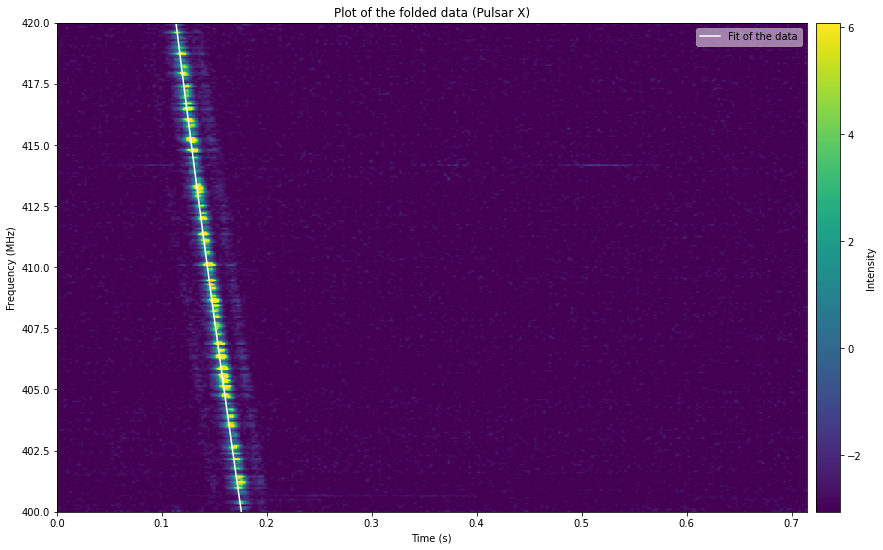

In [28]:
fig = plt.figure(figsize=(16,9))
frame = fig.add_subplot(1,1,1)

frame.imshow(folded, extent=[0, period, freqs.min(), freqs.max()], vmin = 0, vmax = 0.5)
frame.plot(DM_model(freqs, *popt), freqs, color='w', label='Fit of the data')

fig.colorbar(image, ax=frame, pad=0.01, label='Intensity')
frame.set_title(f'Plot of the folded data (Pulsar X)')
frame.set_xlabel('Time (s)')

frame.set_ylabel('Frequency (MHz)')
frame.set_aspect('auto')
frame.legend(framealpha=.5)
plt.show()

<span style="color:blue"><b>Exercise:</b> Improve the dispersion measure fit. <br>Examples of improvements are to improve the masking, remove outliers or to include errors in your datapoints.</span>

<span style="color:green"><b>Suggestion:</b> The dispersion measure is a valueable measurement. Using the position of your pulsar in the galactic plane you can use an electron-density model like [YMW16](http://119.78.162.254/dmodel/index.php) to calculate the distance to the pulsar. You could also try to directly do this in Python using the package [pygedm](https://github.com/FRBs/pygedm).</span>

## De-dispersing the data

Using the determined value of the dispersion measure we can now de-disperse the data. In practice this means that we will remove the slope from the data such that the pulse will be fully aligned in time. We do this by calculating and shifting each frequency bin by its corresponding time delay.


Because my DM is incorrectly calculated, this will not work that well, as visible in the plots below! 

/tmp/ipykernel_3654006/2745036984.py:13: UserWarning: Adding colorbar to a different Figure <Figure size 1152x648 with 2 Axes> than <Figure size 1152x648 with 2 Axes> which fig.colorbar is called on.
  fig.colorbar(image, ax=frame, pad=0.01, label='Intensity')


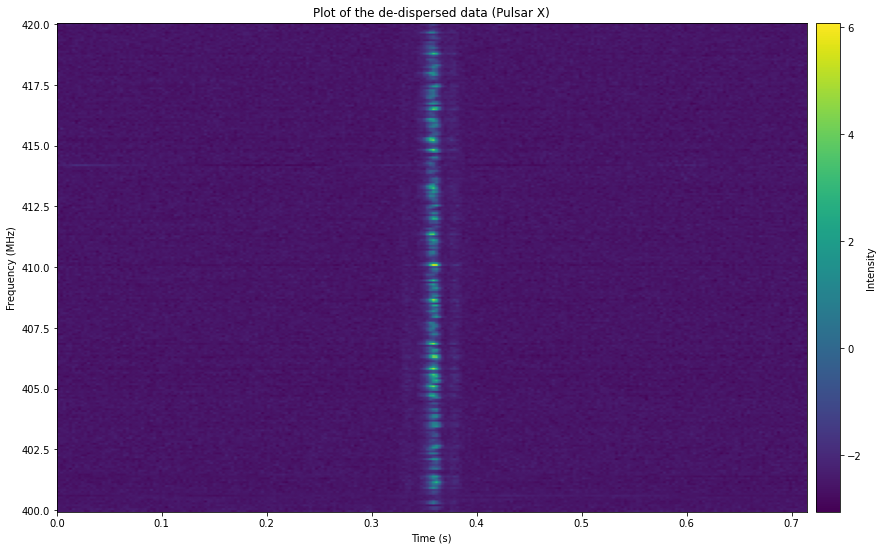

In [29]:
## Creating a new array to fill in ##
data_dm_corrected = np.zeros_like(folded)
bin_width_s = period / folded.shape[1]

## Iterating over each frequency bin and then calculating and applying the respective time delay ##
for freq_nr, freq_mhz in enumerate(freqs):
    time_shift_s = DM_model(freqs, *popt)
    time_shift_bins = int(np.round(time_shift_s[freq_nr] / bin_width_s))
    data_dm_corrected[freq_nr, :] = np.roll(folded[freq_nr, :], - time_shift_bins - int(nbins/2))   # Shifts the pulse in case it's not centered

## Plotting the de-dispersed folded pulse ##
fig, frame = plt.subplots(figsize=(16, 9))
fig.colorbar(image, ax=frame, pad=0.01, label='Intensity')
frame.imshow(data_dm_corrected, extent=[0, period, 400 - 0.137/2, 420 + 0.137/2])
frame.set_title(f'Plot of the de-dispersed data (Pulsar X)')
frame.set_aspect('auto')
frame.set_xlabel("Time (s)")
frame.set_ylabel("Frequency (MHz)")

plt.show()

## Creating a final pulse profile

Aligning all the frequency bins has allowed us to collapse our data along the frequency axis. Doing this will result in a final pulse profile for our data. The final profile for our data can be seen below:

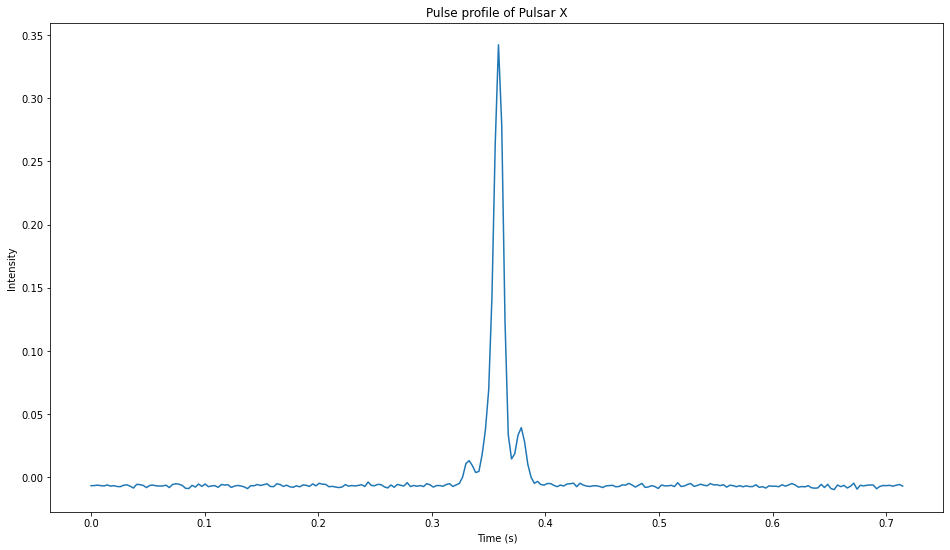

In [30]:
## Collapsing the data ##
final_pulse = np.nanmean(data_dm_corrected, axis=0)
time_array = np.linspace(0, period, data_dm_corrected.shape[1])

## Plotting the final pulse profile ##
fig, frame = plt.subplots(figsize=(16, 9))
frame.plot(time_array, final_pulse)
                
frame.set_title(f'Pulse profile of Pulsar X')
frame.set_aspect('auto')
frame.set_xlabel("Time (s)")
frame.set_ylabel("Intensity")

plt.show()

## Fitting Gaussian

Fitted parameters are: [ 0.33938637  0.35854469 -0.0044978  -0.00532917]


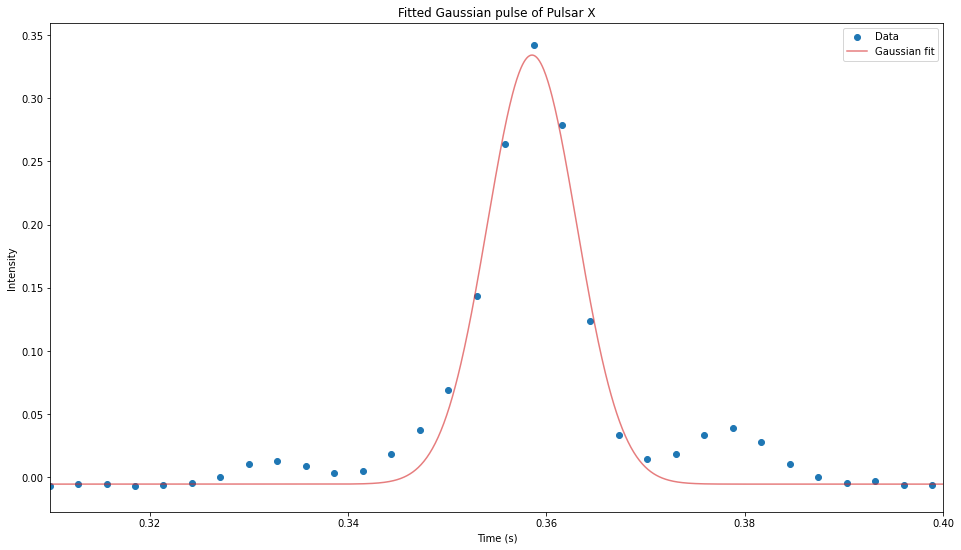

In [32]:
## Estimate initial conditions for your parameters ##
A0 = final_pulse.max() - np.median(final_pulse)
mu0 = 0.35
sigma0 = 0.1
C0 = np.median(final_pulse)

p0 = [A0, mu0, sigma0, C0]

## Fitting the data ##
popt_gauss, pcov_gauss = curve_fit(gaussian, time_array, final_pulse, p0=p0)
print(f"Fitted parameters are: {popt_gauss}".format(*popt_gauss))

cont_time = np.linspace(0, period, 10000)

## Plotting the fit ##
fig, frame = plt.subplots(figsize=(16, 9))
frame.scatter(time_array, final_pulse, label="Data", c='C0')
frame.plot(cont_time, gaussian(cont_time, *popt_gauss), label="Gaussian fit", c='C3', alpha=0.6)

frame.set_title(f'Fitted Gaussian pulse of Pulsar X')
frame.set_aspect('auto')
frame.set_xlabel("Time (s)")
frame.set_ylabel("Intensity")
frame.legend()
frame.set_xlim(0.31, 0.40)  # Zooming in on the pulse

plt.show()